In [1]:
1+1

2

In [2]:

from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END

from langgraph.graph.message import add_messages





In [3]:
class State(TypedDict):
    messages: Annotated[list,add_messages]

graph_builder = StateGraph(State)

In [4]:
graph_builder

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4.1",temperature = 0.3)


In [7]:
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.3', 'langchain': '1.4.2', 'langchain-openai': '1.6.2'}}, profile={'name': 'GPT-4.1', 'release_date': '2025-04-14', 'last_updated': '2025-04-14', 'open_weights': False, 'max_input_tokens': 1047576, 'max_output_tokens': 32768, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001D39C7EAE50>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000001D39C7EBF10>, root_client=<openai.OpenAI object at 0x000001D39C757290>, r

In [8]:
##Node functionality
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [9]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot",chatbot)

graph_builder.add_edge(START,"llmchatbot")

graph_builder.add_edge("llmchatbot",END)

##compile the graph

graph = graph_builder.compile()

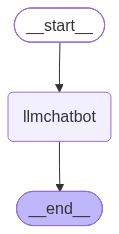

In [10]:
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Failed:", repr(e))



In [11]:
response = graph.invoke({"messages": "Hi, how are you?"})
response["messages"][-1].content

"Hello! I'm just a virtual assistant, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?"

In [12]:
from langchain.tools import tool
from typing import List
@tool
def calculate_sum(numbers: List[float]) -> float:
    """Calculate the sum of a list of numbers."""
    return sum(numbers)


In [13]:
tools = [calculate_sum]

In [19]:
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)

memory = MemorySaver()

In [21]:
def call_model(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [22]:
##Graph with tools
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot",call_model)
graph_builder.add_node("tools",tool_node)

graph_builder.add_edge(START,"llmchatbot")
## tools_condition routes to "tools" if the model made tool calls, otherwise to END
graph_builder.add_conditional_edges("llmchatbot",tools_condition)
graph_builder.add_edge("tools","llmchatbot")

graph = graph_builder.compile(checkpointer = memory)

In [24]:
config = {"configurable": {"thread_id": "1"}}

response = graph.invoke({"messages": "Hi, my name is John."}, config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi, my name is John.
================================== Ai Message ==================================

Hello, John! How can I help you today?


In [25]:
response = graph.invoke({"messages": "What is my name?"}, config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi, my name is John.
================================== Ai Message ==================================

Hello, John! How can I help you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is John.


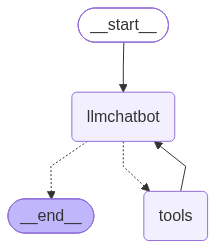

In [18]:
##Visualize the graph with tools
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Failed:", repr(e))